# 01 · Suavização Exponencial (Simples, Holt, Holt-Winters)

**PNV-3421 — Processos Estocásticos — Previsão de Demanda**
**Ementa, tópico 1:** *"Séries temporais: suavizamento exponencial com tendência e sazonalidade"*

### De onde vem este material
O material de aula (`2.1`/`2.2`/`2.3`, notebook `PNV3421_Aula09_ARIMA.ipynb`) só trata de **suavização exponencial simples**, e apenas como contraponto para apresentar os modelos AR/MA — sem tendência, sem sazonalidade. Este notebook retoma aquele conteúdo e o **completa**, cobrindo o tópico 1 da Ementa por inteiro: suavização simples → com tendência (Holt) → com tendência e sazonalidade (Holt-Winters).

### Roteiro
1. Suavização Exponencial Simples (SES) — fórmula, papel de α, limitações
2. Suavização com Tendência (Holt) — nível + tendência, α e β
3. Suavização com Tendência e Sazonalidade (Holt-Winters) — aditivo vs. multiplicativo, α/β/γ
4. Comparação visual SES vs. Holt vs. Holt-Winters na mesma série
5. SES vs. modelos AR/MA (por que suavização simples não é suficiente quando há correlação forte)
6. Exercício resolvido: demanda de contêineres em um terminal portuário

> Convenção de tema: para tornar os exemplos mais próximos da área de Engenharia Naval, usaremos como pano de fundo a **demanda semanal por operações de atracação/carga em um terminal portuário**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(42)

## 1. Suavização Exponencial Simples (SES)

A ideia: a previsão para o próximo período é uma **média ponderada** entre o último valor observado e a última previsão, dando mais peso a observações recentes.

$$\hat Y_{t+1} = \alpha Y_t + (1-\alpha)\hat Y_t, \qquad 0 < \alpha \le 1$$

Expandindo a recursão, o peso de cada observação passada decai geometricamente:

$$\hat Y_{t+1} = \alpha Y_t + \alpha(1-\alpha) Y_{t-1} + \alpha(1-\alpha)^2 Y_{t-2} + \dots$$

* **α grande** (perto de 1): segue de perto as oscilações recentes — reage rápido, mas é "nervoso" (ruidoso).
* **α pequeno** (perto de 0): suaviza bastante — estável, mas demora a reagir a mudanças reais de nível.
* A SES **não tem termo de tendência nem de sazonalidade**: se a série tiver uma delas, a previsão de SES fica sistematicamente atrasada (veja a Seção 4).

**Nível inicial:** por convenção, $\hat Y_1 = Y_1$ (ou a média dos primeiros valores).

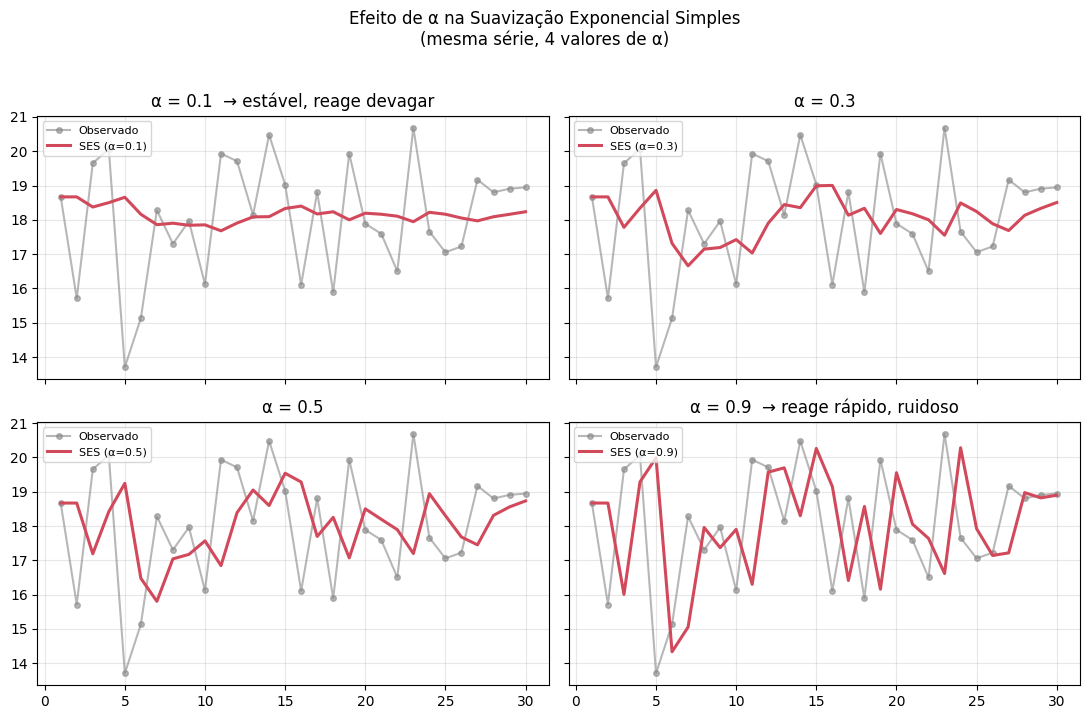

In [2]:
# Série "demanda" (lúdica): número de navios atracados por semana, nível ~ constante com ruído
n = 30
semanas = np.arange(1, n + 1)
demanda_estavel = 18 + rng.normal(0, 2.2, n)

def ses_manual(y, alpha):
    # Implementação manual da SES, célula a célula, para deixar a fórmula visível.
    fit = np.empty(len(y))
    fit[0] = y[0]
    for t in range(1, len(y)):
        fit[t] = alpha * y[t - 1] + (1 - alpha) * fit[t - 1]
    return fit

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
alphas = [0.1, 0.3, 0.5, 0.9]
for ax, alpha in zip(axes.ravel(), alphas):
    suavizada = ses_manual(demanda_estavel, alpha)
    ax.plot(semanas, demanda_estavel, 'o-', color='#888', alpha=0.6, label='Observado', ms=4)
    ax.plot(semanas, suavizada, color='#d1495b', lw=2.2, label=f'SES (α={alpha})')
    ax.set_title(f'α = {alpha}' + ('  → reage rápido, ruidoso' if alpha >= 0.7 else '  → estável, reage devagar' if alpha <= 0.2 else ''))
    ax.legend(fontsize=8, loc='upper left')
fig.suptitle('Efeito de α na Suavização Exponencial Simples\n(mesma série, 4 valores de α)', y=1.02)
fig.tight_layout()
plt.show()

**Leitura do painel acima:** com α pequeno (0,1) a curva mal se move — ótimo se a série for realmente estável e você quiser ignorar ruído; com α grande (0,9) a curva praticamente *copia* a observação anterior, reagindo (talvez demais) a cada oscilação. Este é o trade-off central: **suavidade vs. capacidade de reação**.

### Jogo rápido — tente prever antes de rodar a célula seguinte
Veja as 10 primeiras semanas da série abaixo. Qual seria a sua estimativa (de cabeça) para a semana 11? Depois rode a célula seguinte e compare com a previsão da SES ótima.

In [3]:
print("Semanas 1-10:", np.round(demanda_estavel[:10], 1))
print("\n(Pense na sua estimativa para a semana 11 antes de prosseguir...)")

Semanas 1-10: [18.7 15.7 19.7 20.1 13.7 15.1 18.3 17.3 18.  16.1]

(Pense na sua estimativa para a semana 11 antes de prosseguir...)


In [4]:
# Revelando: ajuste automático do alpha ótimo via statsmodels (minimiza SSE)
modelo_ses = SimpleExpSmoothing(demanda_estavel[:10], initialization_method='estimated').fit()
alpha_otimo = modelo_ses.params['smoothing_level']
previsao_11 = modelo_ses.forecast(1)[0]
print(f"alpha ótimo (ajustado pelo statsmodels): {alpha_otimo:.3f}")
print(f"Previsão da SES para a semana 11: {previsao_11:.2f} navios")
print(f"Valor real observado na semana 11: {demanda_estavel[10]:.2f} navios")

alpha ótimo (ajustado pelo statsmodels): 0.000
Previsão da SES para a semana 11: 17.26 navios
Valor real observado na semana 11: 19.93 navios


## 2. Suavização Exponencial com Tendência — Modelo de Holt

Quando a série tem uma tendência (crescimento ou queda sistemática), a SES simples fica sempre "atrás" da série. O **modelo de Holt** soma um segundo componente, a **tendência estimada** $T_t$, suavizada com seu próprio peso $\beta$:

$$\text{Nível:} \quad L_t = \alpha Y_t + (1-\alpha)(L_{t-1} + T_{t-1})$$
$$\text{Tendência:} \quad T_t = \beta (L_t - L_{t-1}) + (1-\beta) T_{t-1}$$
$$\text{Previsão } h \text{ passos à frente:} \quad \hat Y_{t+h} = L_t + h\,T_t$$

* $\alpha$ controla quão rápido o **nível** se adapta.
* $\beta$ controla quão rápido a **tendência** se adapta (se $\beta=0$, a tendência fica fixa desde a inicialização).
* Ao contrário da SES, a previsão de Holt para $h$ passos à frente **não é uma reta horizontal** — ela projeta a tendência estimada para a frente.

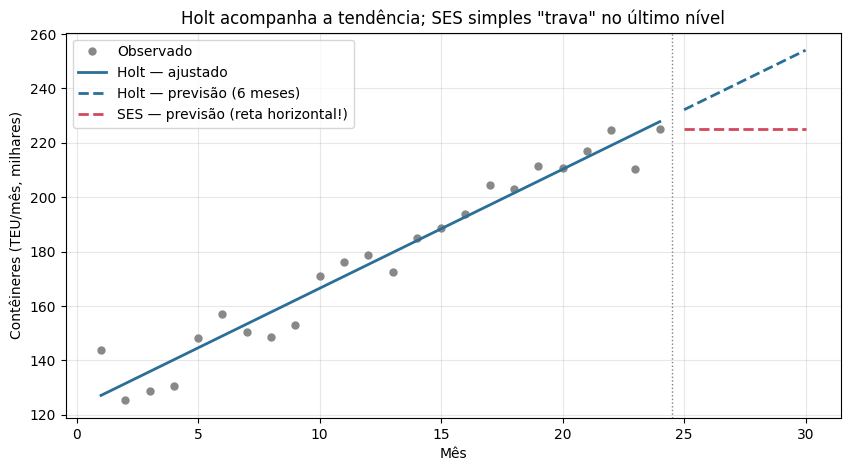

alpha = 0.000   beta = 0.000


In [5]:
# Série com tendência de crescimento: demanda de contêineres crescendo ao longo de 2 anos (24 meses)
meses = np.arange(1, 25)
tendencia_real = 120 + 4.5 * meses
demanda_tendencia = tendencia_real + rng.normal(0, 9, len(meses))

modelo_holt = Holt(demanda_tendencia, initialization_method='estimated').fit()
ajustado_holt = modelo_holt.fittedvalues
previsao_holt = modelo_holt.forecast(6)

modelo_ses_tend = SimpleExpSmoothing(demanda_tendencia, initialization_method='estimated').fit()
previsao_ses_tend = modelo_ses_tend.forecast(6)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(meses, demanda_tendencia, 'o', color='#888', ms=5, label='Observado')
ax.plot(meses, ajustado_holt, color='#2a6f97', lw=2, label='Holt — ajustado')
meses_futuro = np.arange(25, 31)
ax.plot(meses_futuro, previsao_holt, '--', color='#2a6f97', lw=2, label='Holt — previsão (6 meses)')
ax.plot(meses_futuro, previsao_ses_tend, '--', color='#d1495b', lw=2, label='SES — previsão (reta horizontal!)')
ax.axvline(24.5, color='gray', ls=':', lw=1)
ax.set_title('Holt acompanha a tendência; SES simples "trava" no último nível')
ax.set_xlabel('Mês'); ax.set_ylabel('Contêineres (TEU/mês, milhares)')
ax.legend()
plt.show()

print(f"alpha = {modelo_holt.params['smoothing_level']:.3f}   beta = {modelo_holt.params['smoothing_trend']:.3f}")

**O ponto lúdico aqui:** note como a previsão da SES "trava" numa reta horizontal — ela não sabe que a série está subindo. Já o Holt projeta a tendência estimada. Se a demanda realmente continuar subindo, Holt erra muito menos.

## 3. Suavização com Tendência e Sazonalidade — Holt-Winters

Quando, além da tendência, a série tem um padrão que se repete a cada $s$ períodos (ex.: sazonalidade mensal, trimestral), usamos **Holt-Winters**, que soma um terceiro componente sazonal $S_t$, com peso $\gamma$.

**Versão aditiva** (amplitude da sazonalidade ~constante):
$$L_t = \alpha(Y_t - S_{t-s}) + (1-\alpha)(L_{t-1}+T_{t-1})$$
$$T_t = \beta(L_t - L_{t-1}) + (1-\beta)T_{t-1}$$
$$S_t = \gamma(Y_t - L_t) + (1-\gamma)S_{t-s}$$
$$\hat Y_{t+h} = L_t + h\,T_t + S_{t+h-s}$$

**Versão multiplicativa** (amplitude da sazonalidade cresce com o nível):
$$L_t = \alpha\frac{Y_t}{S_{t-s}} + (1-\alpha)(L_{t-1}+T_{t-1}), \qquad S_t = \gamma\frac{Y_t}{L_t} + (1-\gamma)S_{t-s}$$
$$\hat Y_{t+h} = (L_t + h\,T_t)\, S_{t+h-s}$$

Regra prática (a mesma ideia do notebook de decomposição aditiva/multiplicativa): se os "picos e vales" sazonais têm **tamanho fixo em valor absoluto**, use o modelo aditivo; se crescem **proporcionalmente ao nível**, use o multiplicativo.

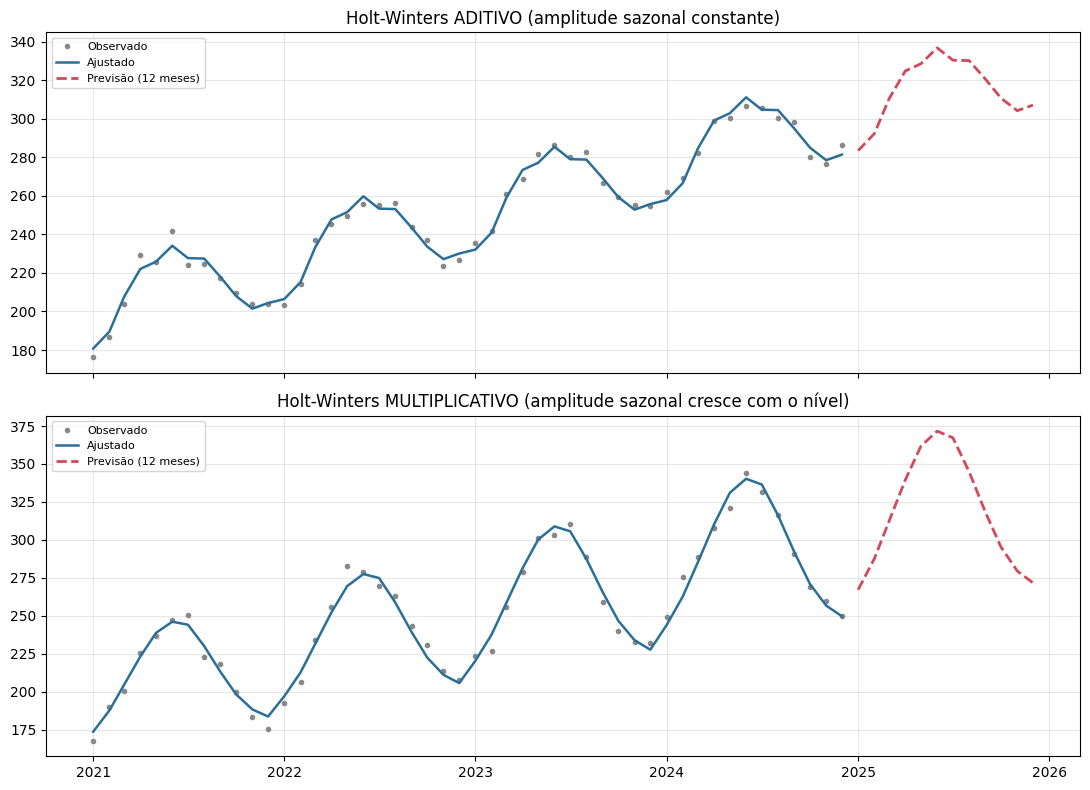

In [6]:
# Série com tendência + sazonalidade anual (12 meses), 4 anos de histórico
n_meses = 48
t = np.arange(n_meses)
tendencia = 200 + 2.2 * t
sazonal_aditiva = 25 * np.sin(2 * np.pi * t / 12 - 1.0)   # amplitude fixa
serie_aditiva = tendencia + sazonal_aditiva + rng.normal(0, 6, n_meses)

fator_sazonal_mult = 1 + 0.18 * np.sin(2 * np.pi * t / 12 - 1.0)   # amplitude proporcional
serie_multiplicativa = tendencia * fator_sazonal_mult + rng.normal(0, 6, n_meses)

datas = pd.date_range('2021-01-01', periods=n_meses, freq='MS')
s_add = pd.Series(serie_aditiva, index=datas)
s_mul = pd.Series(serie_multiplicativa, index=datas)

hw_add = ExponentialSmoothing(s_add, trend='add', seasonal='add', seasonal_periods=12,
                               initialization_method='estimated').fit()
hw_mul = ExponentialSmoothing(s_mul, trend='add', seasonal='mul', seasonal_periods=12,
                               initialization_method='estimated').fit()

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for ax, s, modelo, titulo in [
    (axes[0], s_add, hw_add, 'Holt-Winters ADITIVO (amplitude sazonal constante)'),
    (axes[1], s_mul, hw_mul, 'Holt-Winters MULTIPLICATIVO (amplitude sazonal cresce com o nível)'),
]:
    ax.plot(s.index, s.values, 'o', color='#888', ms=3, label='Observado')
    ax.plot(s.index, modelo.fittedvalues, color='#2a6f97', lw=1.8, label='Ajustado')
    prev = modelo.forecast(12)
    ax.plot(prev.index, prev.values, '--', color='#d1495b', lw=2, label='Previsão (12 meses)')
    ax.set_title(titulo)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 4. Comparação lado a lado: SES vs. Holt vs. Holt-Winters

Vamos aplicar os **três** métodos à mesma série (a com tendência + sazonalidade aditiva) para visualizar, de forma direta, o que cada um "enxerga" — e o que cada um ignora.

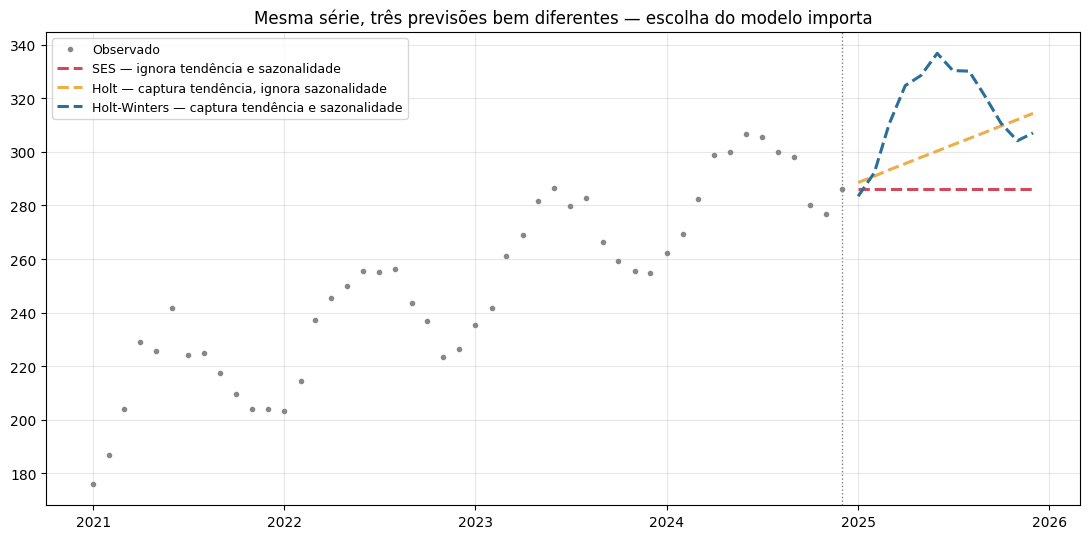

Erro quadrático médio do ajuste (quanto menor, melhor o modelo se encaixou ao passado):
  SES           : MSE =   105.95
  Holt          : MSE =   100.57
  Holt-Winters  : MSE =    10.63


In [7]:
ses_cmp = SimpleExpSmoothing(s_add, initialization_method='estimated').fit()
holt_cmp = Holt(s_add, initialization_method='estimated').fit()
hw_cmp = ExponentialSmoothing(s_add, trend='add', seasonal='add', seasonal_periods=12,
                               initialization_method='estimated').fit()

h = 12
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(s_add.index, s_add.values, 'o', color='#888', ms=3, label='Observado')

idx_fut = pd.date_range(s_add.index[-1] + pd.DateOffset(months=1), periods=h, freq='MS')
for modelo, cor, nome in [
    (ses_cmp, '#d1495b', 'SES — ignora tendência e sazonalidade'),
    (holt_cmp, '#edae49', 'Holt — captura tendência, ignora sazonalidade'),
    (hw_cmp, '#2a6f97', 'Holt-Winters — captura tendência e sazonalidade'),
]:
    prev = modelo.forecast(h)
    ax.plot(idx_fut, prev, '--', lw=2.2, color=cor, label=nome)

ax.axvline(s_add.index[-1], color='gray', ls=':', lw=1)
ax.set_title('Mesma série, três previsões bem diferentes — escolha do modelo importa')
ax.legend(fontsize=9, loc='upper left')
fig.tight_layout()
plt.show()

print("Erro quadrático médio do ajuste (quanto menor, melhor o modelo se encaixou ao passado):")
for modelo, nome in [(ses_cmp, 'SES'), (holt_cmp, 'Holt'), (hw_cmp, 'Holt-Winters')]:
    mse = np.mean((modelo.fittedvalues - s_add.values) ** 2)
    print(f"  {nome:14s}: MSE = {mse:8.2f}")

**Leitura lúdica do gráfico:** a SES (vermelho) prevê uma linha reta no último nível — ignora completamente que a série sobe e que tem um padrão sazonal. O Holt (amarelo) ao menos projeta a subida, mas erra ao não antecipar os picos/vales sazonais. Só o Holt-Winters (azul) reproduz a "dança" sazonal futura. **Regra de ouro:** use sempre o modelo mais simples que capture os componentes realmente presentes na série — Holt-Winters não é "sempre melhor" se não houver sazonalidade de fato (adiciona parâmetros sem necessidade).

## 5. Por que suavização simples não basta quando há correlação forte entre vizinhos

No material de referência da disciplina (ver `04_ARIMA_Box_Jenkins.ipynb`, Seção 3), compara-se a suavização exponencial simples com os modelos **AR** e **MA**: quando a série tem **autocorrelação negativa** forte (valores vizinhos tendem a alternar — "zigue-zague"), a SES só consegue "seguir o nível" (ignorando a estrutura de correlação), e o melhor que ela consegue é usar $\alpha \approx 0$. Já os modelos AR/MA, por explorarem a correlação com defasagens específicas, reduzem o erro em até ~25% nesse cenário. A suavização exponencial é, em essência, um caso particular (pesos fixos, geometricamente decrescentes) dentro da família mais ampla ARIMA — ver Seção 3 de `04_ARIMA_Box_Jenkins.ipynb` para o paralelo formal entre SES e um MA de ordem infinita.

## 6. Exercício resolvido — Demanda de contêineres em terminal portuário

**Enunciado:** um terminal portuário registra o número de contêineres (TEU, em centenas) movimentados por trimestre nos últimos 5 anos. A operação está em expansão (tendência de crescimento) e há um pico sazonal recorrente no 4º trimestre (fim de ano). Ajuste o modelo de suavização mais adequado e produza a previsão para os próximos 4 trimestres.

**Solução:**
1. A série tem tendência **e** sazonalidade → não cabe SES nem Holt puro: é caso de **Holt-Winters**.
2. Precisamos decidir aditivo vs. multiplicativo olhando a amplitude sazonal ao longo do tempo.
3. Ajustamos o modelo e extraímos a previsão.

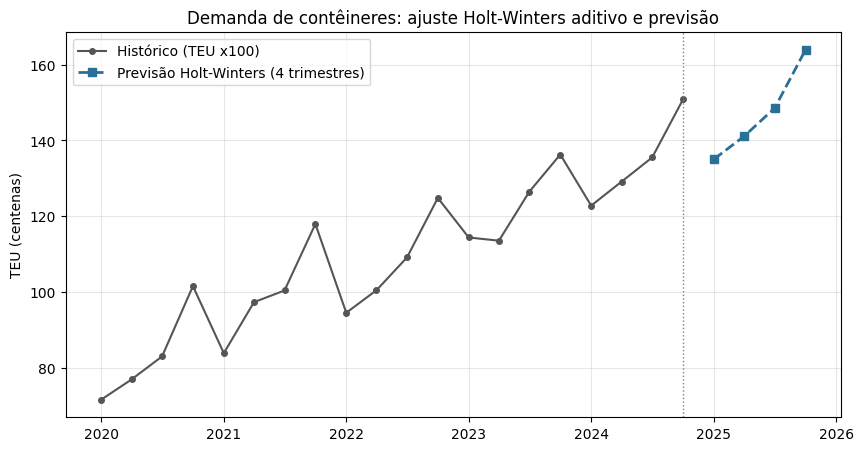

Parâmetros ajustados:
  alpha (nível)     = 0.000
  beta  (tendência) = 0.000
  gamma (sazonal)   = 0.000

Previsão para os próximos 4 trimestres (TEU x100):
2025-01-01    135.1
2025-04-01    141.1
2025-07-01    148.6
2025-10-01    164.0
Freq: QS-OCT, dtype: float64


In [8]:
anos = 5
trims = anos * 4
tt = np.arange(trims)
tendencia_teu = 80 + 3.0 * tt
padrao_trimestral = np.array([-8, -3, 2, 14])   # Q1..Q4: pico no Q4 (temporada de fim de ano)
sazonal_teu = np.tile(padrao_trimestral, anos)
serie_teu = tendencia_teu + sazonal_teu + rng.normal(0, 3, trims)

datas_teu = pd.period_range('2020Q1', periods=trims, freq='Q').to_timestamp()
s_teu = pd.Series(serie_teu, index=datas_teu)

modelo_teu = ExponentialSmoothing(s_teu, trend='add', seasonal='add', seasonal_periods=4,
                                   initialization_method='estimated').fit()
previsao_teu = modelo_teu.forecast(4)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(s_teu.index, s_teu.values, 'o-', color='#555', ms=4, label='Histórico (TEU x100)')
ax.plot(previsao_teu.index, previsao_teu.values, 's--', color='#2a6f97', ms=6, lw=2,
        label='Previsão Holt-Winters (4 trimestres)')
ax.axvline(s_teu.index[-1], color='gray', ls=':', lw=1)
ax.set_title('Demanda de contêineres: ajuste Holt-Winters aditivo e previsão')
ax.set_ylabel('TEU (centenas)')
ax.legend()
plt.show()

print('Parâmetros ajustados:')
print(f"  alpha (nível)     = {modelo_teu.params['smoothing_level']:.3f}")
print(f"  beta  (tendência) = {modelo_teu.params['smoothing_trend']:.3f}")
print(f"  gamma (sazonal)   = {modelo_teu.params['smoothing_seasonal']:.3f}")
print('\nPrevisão para os próximos 4 trimestres (TEU x100):')
print(previsao_teu.round(1))

**Conclusão do exercício:** o modelo captura corretamente o pico recorrente do 4º trimestre dentro da tendência de crescimento — algo que nem SES nem Holt puro conseguiriam reproduzir. Esse é o ganho prático de se caminhar de SES → Holt → Holt-Winters conforme a série exige.

---
*Próximo notebook da sequência: [`02_Correlacao_e_Regressao_Linear.ipynb`](02_Correlacao_e_Regressao_Linear.ipynb) — modelos causais de previsão.*